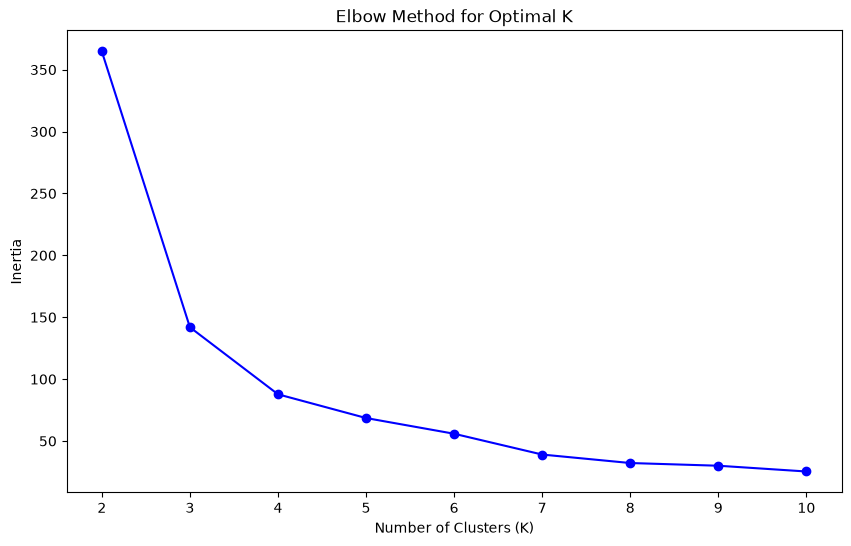

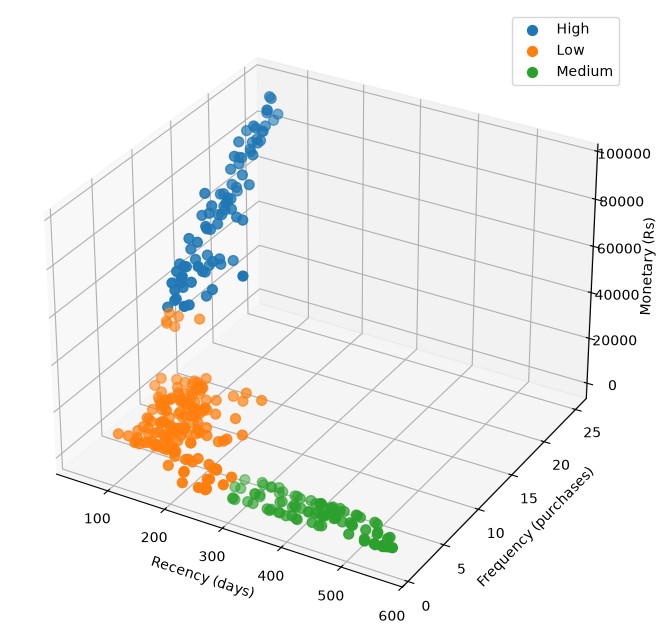

Total Customers: 340

Segment Counts:
SegmentName
Low       166
Medium     90
High       84
Name: count, dtype: int64

Segment Profiles:
             Recency  Frequency  Monetary
SegmentName                              
High            69.7       17.1   64240.5
Low            148.3        5.5    8926.2
Medium         422.1        2.0    1329.3

Recommendations:
High: VIP treatment, priority service, exclusive rewards
Medium: Targeted upsells, loyalty campaigns, cross-sells
Low: Win-back offers, special discounts, re-engagement emails


In [1]:
import pandas as pd
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df = pd.read_csv('/home/username/Downloads/customer_transactions.csv')
df['Date'] = pd.to_datetime(df['Date'])

referenceDate = datetime(2026, 7, 20)

rfm = df.groupby('CustomerID').agg({
    'Date' : lambda x : (referenceDate - x.max()).days,
    'TransactionID' : 'count',
    'Amount' : 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

scaler = StandardScaler()
rfmScaled = scaler.fit_transform(rfm)

inertias = []
KRange = range(2, 11)
for k in KRange:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfmScaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(KRange, inertias, 'bo-')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42)
rfm['Segment'] = kmeans.fit_predict(rfmScaled)

rawProfiles = rfm.groupby('Segment').agg({
    'Recency' : 'mean',
    'Frequency' : 'mean',
    'Monetary' : 'mean'
})

segmentNames = {
    0: 'Low',
    1: 'Medium',
    2: 'High'
}

rfm['SegmentName'] = rfm['Segment'].map(segmentNames)

segmentProfiles = rfm.groupby('SegmentName').agg({
    'Recency' : 'mean',
    'Frequency' : 'mean',
    'Monetary' : 'mean'
}).round(1)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

for segment in rfm['SegmentName'].unique():
    mask = rfm['SegmentName'] == segment
    ax.scatter(
        rfm[mask]['Recency'],
        rfm[mask]['Frequency'],
        rfm[mask]['Monetary'],
        label=segment,
        s=50
    )

ax.set_xlabel('Recency (days)')
ax.set_ylabel('Frequency (purchases)')
ax.set_zlabel('Monetary (Rs)')
ax.legend()
plt.show()

recommendations = {
    'High': 'VIP treatment, priority service, exclusive rewards',
    'Medium': 'Targeted upsells, loyalty campaigns, cross-sells',
    'Low': 'Win-back offers, special discounts, re-engagement emails'
}

print("Total Customers:", len(rfm))
print("\nSegment Counts:")
print(rfm['SegmentName'].value_counts())
print("\nSegment Profiles:")
print(segmentProfiles)
print("\nRecommendations:")
for segment, rec in recommendations.items():
    print(f"{segment}: {rec}")